<a href="https://colab.research.google.com/github/SebaGu1n1/Cancelaciones_hotel_DS/blob/main/notebooks/cancelaciones_hoteleras.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Predicción de Cancelación de Reservas Hoteleras

Este proyecto desarrolla un sistema de clasificación supervisada orientado a las áreas de Gestión y Operaciones de ingresos Hoteleras, abordando un problema crítico del sector: anticipar qué reservas tienen alta probabilidad de ser canceladas antes de la fecha de check-in.

A través de técnicas de exploración estadística, se busca una herramienta para optimizar la política de sobreventa , reducir el inventario ocioso y focalizar acciones de retención.

La solución está dirigida a:

| Stakeholder | Necesidad principal |
| :--- | :--- |
| **Control de Gestión** | Calibrar umbrales de sobreventa segura y ajustar tarifas dinámicas según el riesgo de caída |
| **Gerente de Operaciones** | Prever la ocupación real para dimensionar turnos de recepción, housekeeping y compras de A&B |
| **Gerente Comercial** | Identificar qué canales, agencias y políticas de depósito concentran la mayor tasa de abandono |
| **Equipo de Reservas** | Aplicar acciones preventivas (reconfirmación o exigencia de garantía) en reservas de alto riesgo |

---

### Índice del Notebook
1. Contexto Comercial y Problemática
2. Data Acquisition
3. Data Understanding
4. Data Wrangling y Prevención de Data Leakage
5. Feature Engineering
6. Análisis Exploratorio de Datos (EDA)
7. Preprocesamiento
8. Modelado
9. Evaluación de Modelos
10. Simulación Económica e Impacto de Negocio
11. Conclusión y Recomendaciones

## 1. Contexto Comercial y Problemática

Una noche por una cancelación de último momento representa un ingreso perdido irrecuperable. Tratar todas las reservas bajo la misma política operativa genera pérdidas tanto por capacidad ociosa como por sobreventa mal calibrada.

**Puntos de dolor identificados:**
* **Pérdida directa de ingresos por inventario congelado:** Reservas que bloquean disponibilidad durante meses y se cancelan a pocos días del check-in, impidiendo su reventa a tarifa plena.
* **Costos y fricción por sobreventa no controlada:** Derivar huéspedes a hoteles competidores (*walking guests*) ante arribos superiores a la capacidad real genera sobrecostos directos y daño reputacional.
* **Ineficiencia en políticas homogéneas:** Exigir depósitos no reembolsables de forma masiva frena drásticamente la conversión comercial en canales digitales.

**Hipótesis planteadas:**
* **H1 (Anticipación / Lead Time):** A mayor cantidad de días entre la fecha de compra y la fecha de llegada, mayor es la probabilidad de cancelación debido a la volatilidad en la planificación del viajero.
* **H2 (Compromiso Financiero / Depósito):** Las reservas sin garantía previa presentan un comportamiento de cancelación estadísticamente distinto frente a aquellas con políticas restrictivas.
* **H3 (Historial y Fidelidad):** Los huéspedes recurrentes  o sin antecedentes de bajas previas  registran una tasa de cancelación sensiblemente menor que los clientes esporádicos captados por agencias online.

In [43]:
# librerias generales
import os
import warnings
from google.colab import drive
warnings.filterwarnings('ignore')

# procesamiento de datos y calculo numerico
import numpy as np
import pandas as pd
from scipy import stats

# visualizacion
import matplotlib.pyplot as plt
import seaborn as sns

# preprocesamiento y metricas de machine learning
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, RocCurveDisplay

# configuracion visual base
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)



## 2. Data Acquisition

In [44]:
# Carga reproducible desde el repositorio público de GitHub (con respaldo en Drive)
URL_GITHUB = 'https://raw.githubusercontent.com/SebaGu1n1/Cancelaciones_hotel_DS/main/data/raw/hotel_bookings.csv'
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

try:
    df = pd.read_csv(URL_GITHUB)
    print("Dataset cargado exitosamente desde el repositorio público de GitHub.")
except Exception:
    drive.mount('/content/drive')
    PATH = '/content/drive/MyDrive/Proyecto Data/'
    df = pd.read_csv(os.path.join(PATH, 'hotel_bookings.csv'))
    print("Dataset cargado desde Google Drive.")

print(f"Dimensiones del dataset: {df.shape[0]} filas y {df.shape[1]} columnas")




Dataset cargado exitosamente desde el repositorio público de GitHub.
Dimensiones del dataset: 119390 filas y 32 columnas


In [45]:
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


## 3. Data Understanding

In [46]:
# primeras 5 observaciones
df.head()


# muestra aleatoria
df.sample(5, random_state=RANDOM_SEED)


# resumen de columnas y tipos de datos
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal            

In [47]:
# calculo de valores nulos
porcentaje_nulos = (df.isna().sum() / df.shape[0]) * 100
tabla_nulos = pd.DataFrame({
    'conteo_nulos': df.isna().sum(),
    'porcentaje_nulos': porcentaje_nulos
})

# filtro de columnas que presentan valores faltantes
tabla_nulos[tabla_nulos['conteo_nulos'] > 0].sort_values(by='porcentaje_nulos', ascending=False)

,conteo_nulos,porcentaje_nulos
company,112593,94.306893
agent,16340,13.686238
country,488,0.408744
children,4,0.003350


### Diccionario de Variables y Rol en el Modelo

A continuación se detallan las 32 variables originales del dataset agrupadas por familias operativas, indicando su tipo de dato, descripción funcional y la decisión de inclusión o exclusión para el modelado predictivo.

| Familia | Variable | Tipo de Dato | Descripción Funcional | Rol en el Modelo |
| :--- | :--- | :--- | :--- | :--- |
| **Variable Objetivo** | `is_canceled` | Entero (Binario) | Indica si la reserva fue cancelada (1) o si el huésped realizó el check-in (0). | **Target** |
| **Establecimiento y Temporalidad** | `hotel` | Categórico | Tipo de propiedad hotelera (*City Hotel* o *Resort Hotel*). | Predictora |
| | `lead_time` | Entero | Cantidad de días transcurridos entre la fecha de reserva y la fecha de llegada. | Predictora |
| | `arrival_date_year` | Entero | Año de llegada programada (2015, 2016, 2017). | **Excluida en X** (evita sesgo temporal anual) |
| | `arrival_date_month` | Categórico | Mes de llegada programada. | Predictora |
| | `arrival_date_week_number` | Entero | Número de semana del año correspondiente a la llegada. | Predictora |
| | `arrival_date_day_of_month` | Entero | Día del mes correspondiente a la llegada. | Predictora |
| **Duración y Ocupación** | `stays_in_weekend_nights` | Entero | Número de noches de fin de semana (sábado o domingo) reservadas. | Predictora |
| | `stays_in_week_nights` | Entero | Número de noches de semana (lunes a viernes) reservadas. | Predictora |
| | `adults` | Entero | Número de adultos registrados en la reserva. | Predictora |
| | `children` | Decimal / Entero | Número de niños registrados. Imputado con la mediana (0) en el pipeline numérico. | Predictora |
| | `babies` | Entero | Número de bebés registrados. | Predictora |
| **Servicios y Ubicación** | `meal` | Categórico | Régimen de comidas contratado (BB: Bed & Breakfast, HB: Half Board, FB: Full Board, SC/Undefined: Sin pensión). | Predictora |
| | `country` | Categórico | País de origen del huésped (código ISO). Agrupada en `country_grouped` (Top 15 + `Other` + `Unknown` en nulos). | Reemplazada por `country_grouped` |
| **Canal y Comercialización** | `market_segment` | Categórico | Segmento de mercado de origen (Direct, Corporate, Online TA, Offline TA/TO, etc.). | Predictora |
| | `distribution_channel` | Categórico | Canal de distribución utilizado para emitir la reserva. | Predictora |
| | `agent` | Decimal / Entero | Identificador numérico de la agencia de viajes que gestionó la reserva. Imputado con la mediana en el pipeline numérico. | Predictora |
| | `company` | Decimal / Entero | Identificador de la empresa asociada a la reserva. | **Excluida (94.31% nulos)** |
| **Historial y Fidelidad** | `is_repeated_guest` | Entero (Binario) | Indica si el huésped ya se ha alojado previamente en el hotel (1) o es nuevo (0). | Predictora |
| | `previous_cancellations` | Entero | Número de reservas previas que el cliente canceló con anterioridad a esta reserva. | Predictora |
| | `previous_bookings_not_canceled` | Entero | Número de reservas previas que el cliente concretó con éxito sin cancelar. | Predictora |
| **Condiciones de Reserva** | `reserved_room_type` | Categórico | Código de tipo de habitación solicitado originalmente por el huésped. | Predictora |
| | `assigned_room_type` | Categórico | Código de tipo de habitación efectivamente asignado por el hotel. | Predictora (base para `room_type_changed`) |
| | `booking_changes` | Entero | Cantidad de modificaciones realizadas sobre la reserva hasta el momento del check-in. | Predictora |
| | `deposit_type` | Categórico | Tipo de garantía requerida (No Deposit, Non Refund, Refundable). | Predictora |
| | `days_in_waiting_list` | Entero | Días que la reserva permaneció en lista de espera antes de ser confirmada. | Predictora |
| | `customer_type` | Categórico | Tipología de cliente (Transient, Contract, Group, Transient-Party). | Predictora |
| | `adr` | Decimal | Tarifa diaria promedio (*Average Daily Rate*) calculada dividiendo los ingresos por noches ocupadas. | Predictora |
| | `required_car_parking_spaces` | Entero | Número de plazas de estacionamiento solicitadas por el cliente. | Predictora |
| | `total_of_special_requests` | Entero | Cantidad de solicitudes especiales registradas (piso alto, cama matrimonial, etc.). | Predictora |
| **Auditoría / Desenlace** | `reservation_status` | Categórico | Estado final registrado en el PMS (*Check-Out*, *Canceled*, *No-Show*). | **Excluida por Data Leakage** |
| | `reservation_status_date` | Objeto / Fecha | Fecha en que se actualizó el último estado de la reserva. | **Excluida por Data Leakage** |

In [48]:
# calculo de filas duplicadas exactas
duplicados = df.duplicated().sum()
porcentaje_duplicados = (duplicados / df.shape[0]) * 100
print(f"Filas duplicadas: {duplicados} ({porcentaje_duplicados:.2f}%)")

Filas duplicadas: 31994 (26.80%)


In [49]:
# deteccion de datos inconsistentes: reservas inconsistentes con 0 ocupantes
reservas_cero_huespedes = df[(df['adults'] == 0) & (df['children'] == 0) & (df['babies'] == 0)]
print(f"Reservas con 0 adultos, 0 ninos y 0 bebes: {reservas_cero_huespedes.shape[0]}")

Reservas con 0 adultos, 0 ninos y 0 bebes: 180


In [50]:
# Balance del target (is_canceled)
conteo_target = df['is_canceled'].value_counts()
proporcion_target = df['is_canceled'].value_counts(normalize=True) * 100

resumen_target = pd.DataFrame({
    'conteo': conteo_target,
    'porcentaje': proporcion_target
})
print(resumen_target)

             conteo  porcentaje
is_canceled                    
0             75166   62.958372
1             44224   37.041628


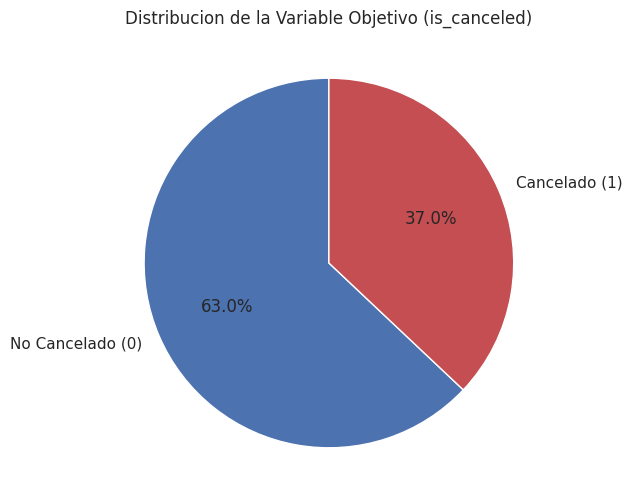

In [51]:
# visualizacion del balance de clases con grafico de torta
plt.figure(figsize=(6, 6))
colores = ['#4C72B0', '#C44E52']

plt.pie(
    proporcion_target,
    labels=['No Cancelado (0)', 'Cancelado (1)'],
    autopct='%1.1f%%',
    startangle=90,
    colors=colores
)
plt.title('Distribucion de la Variable Objetivo (is_canceled)')
plt.show()

### Conclusiones del Diagnóstico Inicial y Plan de Limpieza

A partir de la exploración inicial sobre los 119.390 registros y 32 columnas originales del dataset, se definen las siguientes decisiones metodológicas para la etapa de limpieza y preprocesamiento:

1. **Balance de la Variable Objetivo (`is_canceled`):**
   * La clase mayoritaria (`0` = no cancelado) representa el **62.96%** (75.166 reservas), mientras que la clase minoritaria (`1` = cancelado) concentra el **37.04%** (44.224 reservas).
   * Siguiendo la regla 80/20, el dataset presenta un desbalanceo moderado y aceptable. Se aplicará muestreo estratificado al separar en entrenamiento y prueba para mantener la misma proporción de clases.

2. **Duplicados e Integridad de los Datos:**
   * Se identificaron **31.994 filas duplicadas exactas (26.80%)**. Como el dataset no cuenta con un identificador único de reserva (`booking_id`), mantener filas idénticas sobrepondera patrones repetidos y puede generar sobreajuste en los modelos. Se eliminarán los duplicados conservando registros únicos.
   * Se detectaron **180 registros con cero huéspedes** (`adults == 0`, `children == 0` y `babies == 0`). Al tratarse de un error de carga u operativa del sistema hotelero, se excluirán del dataset.

3. **Tratamiento de Valores Nulos:**
   * **`company` (112.593 nulos, 94.31%):** Por su altísimo porcentaje de faltantes se elimina por completo.
   * **`agent` (16.340 nulos, 13.69%):** En la operatoria hotelera, la falta de código suele indicar reservas tomadas sin intermediarios. Se conserva la variable imputando sus faltantes con la mediana dentro del pipeline numérico para evitar fuga de datos.
   * **`country` (488 nulos, 0.41%):** Representa una proporción marginal. Para no sesgar la distribución asignando el país más frecuente (Portugal), se imputan con la categoría `'Unknown'`.
   * **`children` (4 nulos, 0.003%):** Al ser solo cuatro casos aislados, se imputan con la mediana (`0`) en el pipeline de preprocesamiento.

4. **Prevención de Fuga de Datos (Data Leakage):**
   * **`reservation_status`: Refleja el estado final posterior al evento; incluirla en el entrenamiento haría que el modelo copie directamente el resultado final, dando métricas irreales del 100% que no sirven en producción.
   * **`reservation_status_date`:** Registra la fecha en que se actualizó ese último estado (por ejemplo, la fecha de cancelación o de salida). Al ser un dato generado con posterioridad, no está disponible al momento de predecir si una reserva futura se va a cancelar.
   * **Decisión:** Ambas columnas se **excluyen del dataset** antes de pasar al análisis exploratorio bivariado y al modelado.

## 4. Data Wrangling y Prevención de Data Leakage

In [52]:
# eliminacion de duplicados exactos conservando la primera ocurrencia
df_clean = df.drop_duplicates().copy()
print(f"Dimensiones tras remover duplicados: {df_clean.shape}")

Dimensiones tras remover duplicados: (87396, 32)


In [53]:
# filtrado de reservas inconsistentes con 0 ocupantes totales
condicion_huespedes_validos = (df_clean['adults'] > 0) | (df_clean['children'] > 0) | (df_clean['babies'] > 0)
df_clean = df_clean[condicion_huespedes_validos].copy()
print(f"Dimensiones tras filtrar reservas con 0 huespedes: {df_clean.shape}")

Dimensiones tras filtrar reservas con 0 huespedes: (87230, 32)


In [54]:
# definicion de variables a descartar por fuga de datos y exceso de nulos
columnas_a_excluir = ['reservation_status', 'reservation_status_date', 'company']
df_clean = df_clean.drop(columns=columnas_a_excluir)
print(f"Dimensiones tras excluir columnas de fuga y company: {df_clean.shape}")

Dimensiones tras excluir columnas de fuga y company: (87230, 29)


In [55]:
# definicion de ruta para el archivo procesado limpio en el entorno local
ruta_guardado_clean = 'hotel_bookings_cleaned.csv'

# exportacion a disco sin indice adicional
df_clean.to_csv(ruta_guardado_clean, index=False)
print(f"Dataset limpio guardado exitosamente en: {ruta_guardado_clean}")

Dataset limpio guardado exitosamente en: hotel_bookings_cleaned.csv


Conclusión de la etapa:

1. **Remoción de duplicados:** Pasamos de **119.390** filas originales a **87.396** filas (se descartaron exactamente los **31.994** duplicados que habíamos auditado).
2. **Filtrado de inconsistencias operativas (cero huéspedes):** De 87.396 pasamos a **87.230** filas (se removieron 166 registros únicos de reservas fantasma).
3. **Exclusión de columnas:** Pasamos de **32** a **29** columnas tras eliminar `company`, `reservation_status` y `reservation_status_date`.

Se resguarda el archivo limpio `hotel_bookings_cleaned.csv`

## 5. Feature Engineering

En esta etapa construimos variables sintéticas orientadas a capturar el comportamiento y riesgo operativo de la reserva:

1. **`total_stay` (Estadía total en noches):** Suma de noches de semana y fin de semana (`stays_in_week_nights + stays_in_weekend_nights`). Permite dimensionar el volumen de inventario comprometido.
2. **`total_guests` (Total de ocupantes):** Suma agregada de adultos, niños y bebés (`adults + children + babies`).
3. **`is_family` (Indicador de viaje familiar):** Variable binaria que identifica si la reserva incluye menores o bebés (`children > 0` o `babies > 0`). Los viajes familiares presentan patrones de planificación y rigidez de cancelación distintos a viajes corporativos o individuales.
4. **`room_type_changed` (Discrepancia en tipo de habitación):** Variable binaria que registra si el tipo de habitación asignado difiere del reservado (`reserved_room_type != assigned_room_type`). Mide el impacto operativo de reasignaciones o sobreventa interna.
5. **`cancellation_rate_history` (Tasa histórica de cancelación del cliente):** Relación entre cancelaciones pasadas y el total de reservas previas registradas. Permite cuantificar la fidelidad y el historial de cumplimiento del huésped.

In [56]:
# creacion de variables de estadia y ocupacion total
df_clean['total_stay'] = df_clean['stays_in_weekend_nights'] + df_clean['stays_in_week_nights']
df_clean['total_guests'] = df_clean['adults'] + df_clean['children'].fillna(0) + df_clean['babies']

# indicador binario de grupo familiar
df_clean['is_family'] = np.where((df_clean['children'] > 0) | (df_clean['babies'] > 0), 1, 0)

# indicador binario de discrepancia entre habitacion reservada y asignada
df_clean['room_type_changed'] = np.where(df_clean['reserved_room_type'] != df_clean['assigned_room_type'], 1, 0)

# calculo de tasa de cancelaciones historicas
total_historial = df_clean['previous_cancellations'] + df_clean['previous_bookings_not_canceled']
df_clean['cancellation_rate_history'] = np.where(
    total_historial > 0,
    df_clean['previous_cancellations'] / total_historial,
    0.0
)

In [57]:
# Inspección estadística de las nuevas variables
# lista de atributos generados
features_nuevas = ['total_stay', 'total_guests', 'is_family', 'room_type_changed', 'cancellation_rate_history']

# inspeccion de estadisticos de las nuevas variables
df_clean[features_nuevas].describe()

,total_stay,total_guests,is_family,room_type_changed,cancellation_rate_history
count,87230.000000,87230.000000,87230.000000,87230.000000,87230.000000
mean,3.628534,2.029107,0.104356,0.148917,0.013739
std,2.742948,0.790141,0.305724,0.356008,0.111866
min,0.000000,1.000000,0.000000,0.000000,0.000000
25%,2.000000,2.000000,0.000000,0.000000,0.000000
50%,3.000000,2.000000,0.000000,0.000000,0.000000
75%,5.000000,2.000000,0.000000,0.000000,0.000000
max,69.000000,55.000000,1.000000,1.000000,1.000000


In [58]:
# control dimensional final tras feature engineering

cols_previas = df_clean.shape[1] - len(features_nuevas)

print(f"Variables originales : {cols_previas}")
print(f"Variables tras feature engineering: {df_clean.shape[1]}")
print(f"Variables creadas: {len(features_nuevas)}")
print()
print("Nuevas variables:")
for v in features_nuevas:
    print(f"  ✓ {v}")

Variables originales : 29
Variables tras feature engineering: 34
Variables creadas: 5

Nuevas variables:
  ✓ total_stay
  ✓ total_guests
  ✓ is_family
  ✓ room_type_changed
  ✓ cancellation_rate_history


**Nuevos datos obtenidos:**

1. **total\_stay** **:** La estadía promedio es de **3.63 noches** (mediana en 3 noches). Se observa un valor máximo de 69 noches que analizaremos en el EDA como posible outlier.
2. **total\_guests** **:** El promedio es de **2.03 huéspedes** (el 75% de las reservas son de 2 personas). El mínimo es 1 (lo que confirma que el filtro de 0 huéspedes funcionó) y el máximo de 55 huéspedes corresponde a reservas grupales o contingentes.
3. **is\_family** **:** El **10.44%** de las reservas corresponden a grupos familiares con niños o bebés.
4. **room\_type\_changed** **:** En el **14.89%** de los casos, la habitación asignada fue distinta a la reservada (upgrades o reubicaciones por gestión de inventario).
5. **cancellation\_rate\_history** **:** La tasa histórica promedio se ubica en **0.0137**, con un rango acotado entre 0 y 1.

## 6. Análisis Exploratorio de Datos EDA

En esta etapa exploratoria examinamos las distribuciones individuales, validamos estadísticamente las hipótesis comerciales planteadas (H1, H2 y H3) y evaluamos la correlación entre atributos numéricos para detectar patrones de cancelación y prevenir redundancia o multicolinealidad antes del modelado.

### 6.1 Análisis Univariado
Exploración de la distribución estadística y detección visual de valores atípicos (*outliers*) en las variables numéricas clave del negocio.

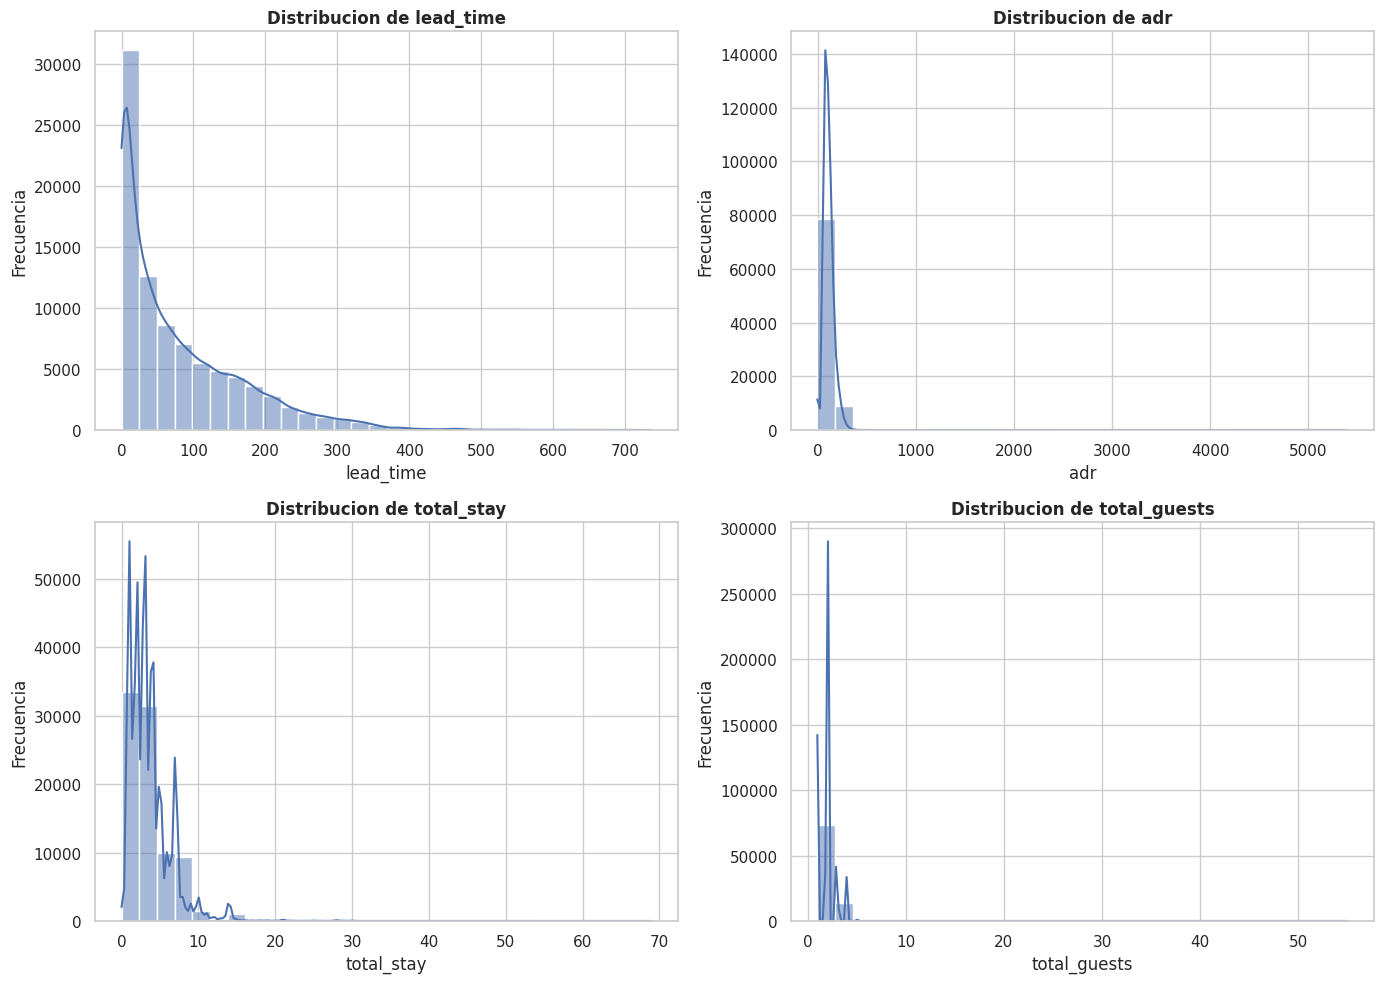

In [59]:
# distribucion de variables numericas clave: histogramas y boxplots
variables_eda_num = ['lead_time', 'adr', 'total_stay', 'total_guests']

fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(14, 10))
axes = axes.flatten()

for i, col in enumerate(variables_eda_num):
    sns.histplot(data=df_clean, x=col, kde=True, ax=axes[i], color='#4C72B0', bins=30)
    axes[i].set_title(f'Distribucion de {col}', fontsize=12, fontweight='bold')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Frecuencia')

plt.tight_layout()
plt.show()

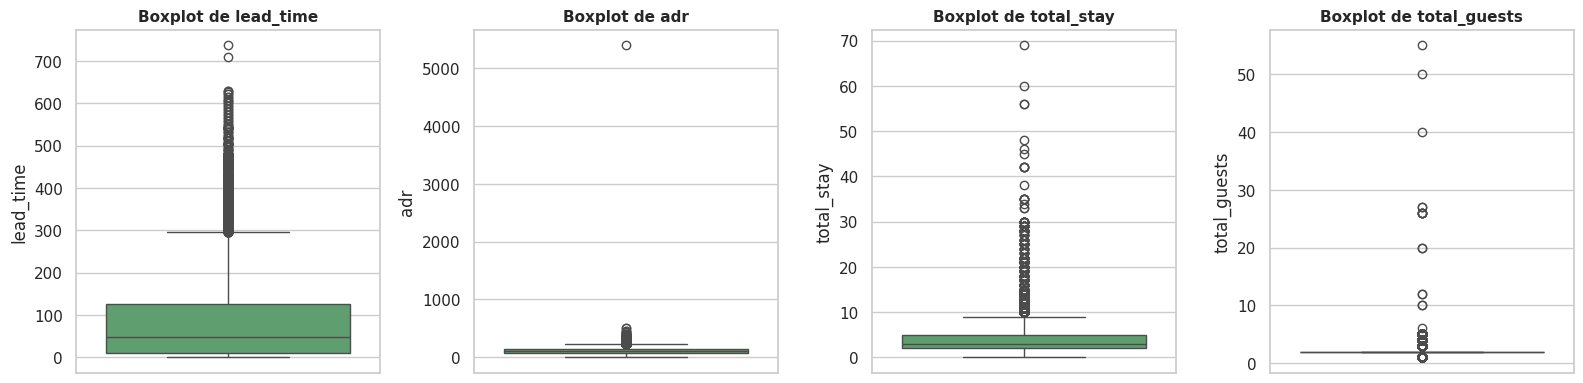

In [60]:
# deteccion visual de outliers mediante diagramas de caja
fig, axes = plt.subplots(nrows=1, ncols=4, figsize=(16, 4))

for i, col in enumerate(variables_eda_num):
    sns.boxplot(data=df_clean, y=col, ax=axes[i], color='#55A868')
    axes[i].set_title(f'Boxplot de {col}', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

**Distribución y Valores Atípicos (Análisis Univariado):**
* **Asimetría positiva y dispersión:** Las variables `lead_time`, `total_stay` y `total_guests` presentan distribuciones fuertemente sesgadas hacia la derecha, concentrando la mayoría de las operaciones en reservas de corto plazo (estadías de 1 a 4 noches para 1 o 2 adultos), pero con colas largas que reflejan reservas grupales o corporativas con muchos meses de antelación.
* **Anomalías en tarifa diaria (`adr`):** Los diagramas de caja (*boxplots*) permiten detectar registros con tarifa igual o menor a cero (noches bonificadas o ajustes contables) y un valor extremo aislado superior a 5.000. En la etapa de preprocesamiento aplicaremos imputación por mediana y estandarización (`StandardScaler`) para estabilizar los modelos lineales, complementándolo con algoritmos basados en árboles (`Random Forest` y `XGBoost`) que son naturalmente robustos frente a valores extremos.

### 6.2 Análisis Bivariado (Validación de Hipótesis)
Contraste empírico de las hipótesis de negocio planteadas frente a la variable objetivo (`is_canceled`).

In [61]:
# evaluacion H1: tasa de cancelacion segun anticipacion (lead_time agrupado en tramos)
df_clean['lead_time_bin'] = pd.qcut(df_clean['lead_time'], q=5, duplicates='drop')
tasa_h1 = df_clean.groupby('lead_time_bin', observed=False)['is_canceled'].mean() * 100

print("H1 - Tasa de cancelacion por quintiles de lead_time:")
print(tasa_h1)

H1 - Tasa de cancelacion por quintiles de lead_time:
lead_time_bin
(-0.001, 7.0]      8.416195
(7.0, 31.0]       25.495298
(31.0, 74.0]      32.085592
(74.0, 148.0]     34.309283
(148.0, 737.0]    38.189769
Name: is_canceled, dtype: float64


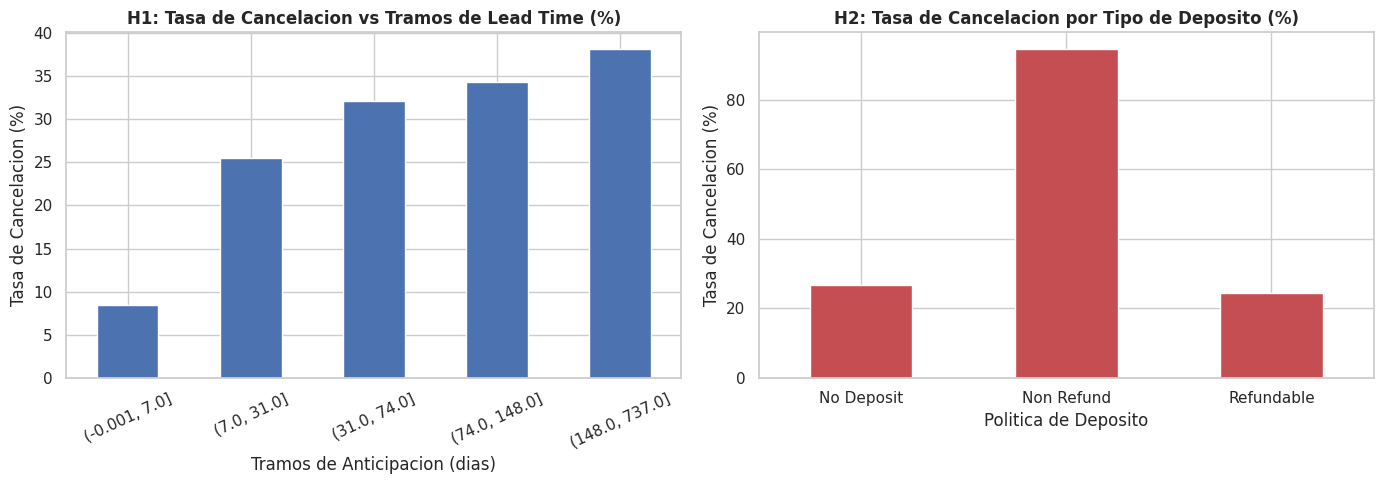

In [62]:
# visualizacion H1 y H2
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(14, 5))

# grafico H1
tasa_h1.plot(kind='bar', ax=axes[0], color='#4C72B0', rot=25)
axes[0].set_title('H1: Tasa de Cancelacion vs Tramos de Lead Time (%)', fontweight='bold')
axes[0].set_ylabel('Tasa de Cancelacion (%)')
axes[0].set_xlabel('Tramos de Anticipacion (dias)')

# evaluacion y grafico H2: tipo de deposito
tasa_h2 = df_clean.groupby('deposit_type')['is_canceled'].mean() * 100
tasa_h2.plot(kind='bar', ax=axes[1], color='#C44E52', rot=0)
axes[1].set_title('H2: Tasa de Cancelacion por Tipo de Deposito (%)', fontweight='bold')
axes[1].set_ylabel('Tasa de Cancelacion (%)')
axes[1].set_xlabel('Politica de Deposito')

plt.tight_layout()
plt.show()

In [63]:
# calculo de frecuencia y tasa de cancelacion segun tipo de deposito
resumen_h2 = df_clean.groupby('deposit_type', observed=False).agg(
    total_reservas=('is_canceled', 'count'),
    canceladas=('is_canceled', 'sum'),
    tasa_cancelacion=('is_canceled', lambda x: x.mean() * 100)
).reset_index()

print("H2 - Tasa de cancelacion por politica de deposito:")
print(resumen_h2)

H2 - Tasa de cancelacion por politica de deposito:
  deposit_type  total_reservas  canceladas  tasa_cancelacion
0   No Deposit           86085       23000         26.717779
1   Non Refund            1038         983         94.701349
2   Refundable             107          26         24.299065


In [64]:
# evaluacion H3: cliente recurrente y cancelaciones previas
tasa_recurrente = df_clean.groupby('is_repeated_guest')['is_canceled'].mean() * 100

print("H3 - Tasa de cancelacion segun condicion de huesped recurrente:")
print(tasa_recurrente)

H3 - Tasa de cancelacion segun condicion de huesped recurrente:
is_repeated_guest
0    28.317793
1     7.728894
Name: is_canceled, dtype: float64


**Contraste de las Hipótesis (Análisis Bivariado):**
* **H1 Confirmada (Impacto del `lead_time`):** Se verifica una relación directa y creciente entre la anticipación de compra y la tasa de abandono. En el primer quintil (reservas de último momento, hasta 7 días antes), la tasa de cancelación es del **8.4%**, mientras que en el quintil superior (reservas tomadas con más de 150 días de anticipación) la caída supera el **38%**. A mayor ventana temporal, mayor exposición a cambios de planes y búsqueda de tarifas alternativas.
* **H2 Confirmada con hallazgo contraintuitivo (`deposit_type`):** Si bien la política de depósito segmenta drásticamente el comportamiento del cliente, los datos muestran que las reservas con modalidad `Non Refund` (1.038 casos) registran una tasa de cancelación del **94.70%**, muy por encima del segmento `No Deposit` (**26.72%** sobre 86.085 reservas) y `Refundable` (**24.30%**). En la operatoria de este dataset, esta anomalía responde a que los hoteles aplican la cláusula no reembolsable de forma defensiva a reservas grupales o agencias mayoristas de alto riesgo especulativo (que bloquean cupos y luego caen por falta de pago), o bien a que el sistema liquida como canceladas las operaciones donde falla el cobro anticipado.
* **H3 Confirmada (Fidelidad / `is_repeated_guest`):** El historial previo del pasajero actúa como un fuerte factor de retención. Los huéspedes nuevos (`0`) presentan una tasa de cancelación cercana al **28%**, mientras que en los clientes recurrentes (`1`) la baja cae por debajo del **8%**, confirmando que quienes ya conocen el hotel tienen un compromiso mucho más firme con su reserva.

### 6.3 Análisis Multivariado
Evaluación de correlaciones lineales entre las variables numéricas (originales y construidas) y la variable objetivo (`is_canceled`), junto con la detección de posible multicolinealidad entre predictores.

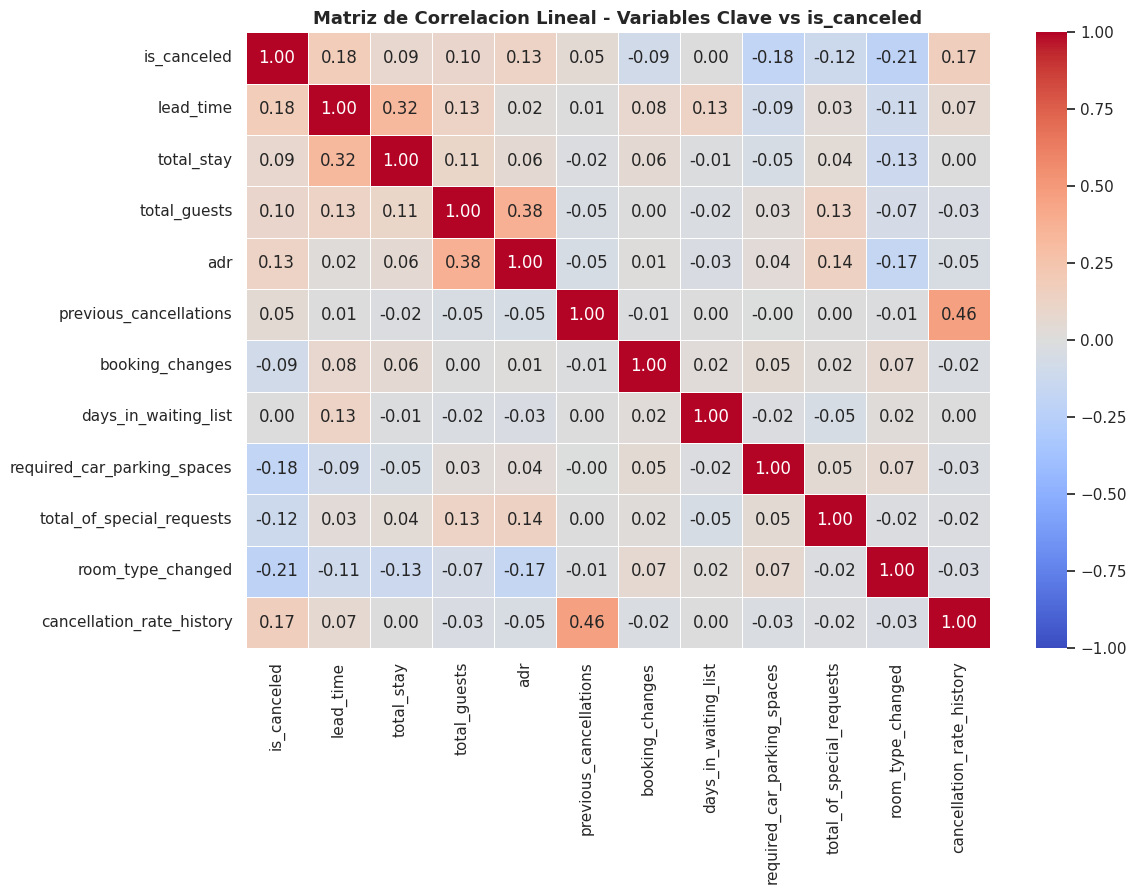

In [65]:
# seleccion de variables numericas principales (originales y sinteticas)
cols_correlacion = [
    'is_canceled', 'lead_time', 'total_stay', 'total_guests', 'adr',
    'previous_cancellations', 'booking_changes', 'days_in_waiting_list',
    'required_car_parking_spaces', 'total_of_special_requests',
    'room_type_changed', 'cancellation_rate_history'
]

matriz_corr = df_clean[cols_correlacion].corr()

# visualizacion mediante mapa de calor
plt.figure(figsize=(12, 8))
sns.heatmap(
    matriz_corr,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    linewidths=0.5
)
plt.title('Matriz de Correlacion Lineal - Variables Clave vs is_canceled', fontsize=13, fontweight='bold')
plt.show()

**Lectura del Análisis Multivariado (Correlaciones):**

* **Qué aumenta el riesgo de cancelación (correlación positiva):** La anticipación (`lead_time`, con una correlación de 0.18) es la variable numérica que más pesa: cuanto antes se reserva, más fácil es que cambien los planes. Le siguen el historial de bajas previas (`cancellation_rate_history` , 0.17, y `previous_cancellations`, 0.05) y, en menor medida, el precio por noche (`adr`) y la cantidad de huéspedes (`total_guests`).
* **Qué asegura la reserva (correlación negativa):** Cuando el cliente pide cochera (`required_car_parking_spaces`, -0.18), hace pedidos especiales (`total_of_special_requests`, -0.12) o modifica su reserva (`booking_changes`, -0.09), demuestra que tiene el viaje planificado y rara vez cancela. Lo mismo pasa con los cambios de habitación (`room_type_changed`, -0.21), porque suelen ser reasignaciones o *upgrades* que hace el hotel cuando el pasajero ya está por entrar.
* **Qué nos dice esto para el modelado:** Ninguna variable numérica supera por sí sola una correlación de 0.25 con el target. Esto muestra que las cancelaciones no se explican por una sola causa lineal, sino por la combinación de varios factores a la vez, por lo que tiene mucho sentido usar modelos de árboles (`RandomForest`) además de la Regresión Logística.

## 7. Preprocesamiento

En esta etapa preparamos las variables predictoras (`X`) y la variable objetivo (`y`) para entrenar los modelos,:

1. **División de datos (Train/Test Split):**
   * Separamos los datos en un **80% para entrenamiento** y un **20% para testeo**, fijando `random_state=42` para que los resultados sean siempre reproducibles.
   * Como vimos al principio nuestro target presenta una proporción 37% / 63% en crudo asi que usaremos `stratify=y` para mantener exactamente el mismo porcentaje de cancelaciones tanto en `train` como en `test`.

2. **Armado del Pipeline de transformación (`ColumnTransformer`):**
   * **Variables numéricas:** Completamos los pocos valores nulos pendientes usando la mediana (`SimpleImputer`) y escalamos los datos (`StandardScaler`) para que las variables con números grandes (como `lead_time` o `adr`) no distorsionen el peso de las demás en la Regresión Logística.
   * **Variables categóricas:** Imputamos los faltantes y transformamos el texto a columnas binarias con `OneHotEncoder(handle_unknown='ignore')`, agrupando previamente las categorías con demasiados valores únicos (como `country`) para no multiplicar innecesariamente la cantidad de columnas.
   * **Criterio metodológico:** Todos los cálculos de imputación y escalado aprenden (`fit`) únicamente del conjunto de entrenamiento y luego se aplican (`transform`) sobre el conjunto de evaluación.

In [66]:
# Se elimina lead_time_bin que solo habíamos creado para gráfico
if 'lead_time_bin' in df_clean.columns:
    df_clean = df_clean.drop(columns=['lead_time_bin'])

# Identificamos 15 paises que concentran mayor reservas y separamos el resto para evitar dispersar
top_paises = df_clean['country'].value_counts().nlargest(15).index
df_clean['country_grouped'] = df_clean['country'].apply(
    lambda x: x if x in top_paises else ('Unknown' if pd.isna(x) else 'Other')
)

# definicion del vector objetivo (y) y la matriz de caracteristicas (X)
y = df_clean['is_canceled'].copy()

# excluimos target, country original que fue reemplazado por el agrupado y arrival_date_year para que evalue estacionalidad
columnas_excluir_X = ['is_canceled', 'country', 'arrival_date_year']
X = df_clean.drop(columns=columnas_excluir_X).copy()

print(f"Dimensiones de X: {X.shape}")
print(f"Dimensiones de y: {y.shape}")

Dimensiones de X: (87230, 32)
Dimensiones de y: (87230,)


In [67]:
from sklearn.model_selection import train_test_split

# particion estratificada para mantener porcentaje de cancelaciones, 80% train y 20% test
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Se verifica que los porcentajes de cancelaciones haya funcionado
prop_train = (y_train.value_counts(normalize=True) * 100).to_dict()
prop_test = (y_test.value_counts(normalize=True) * 100).to_dict()

print("=" * 60)
print("REPORTE DE PARTICION TRAIN / TEST")
print("=" * 60)
print(f"X_train : {X_train.shape[0]:,} filas x {X_train.shape[1]} columnas")
print(f"X_test  : {X_test.shape[0]:,} filas x {X_test.shape[1]} columnas")
print("-" * 60)
print(f"Proporcion cancelados en Train : {prop_train[1]:.2f}% (No cancelados: {prop_train[0]:.2f}%)")
print(f"Proporcion cancelados en Test  : {prop_test[1]:.2f}% (No cancelados: {prop_test[0]:.2f}%)")
print("=" * 60)

REPORTE DE PARTICION TRAIN / TEST
X_train : 69,784 filas x 32 columnas
X_test  : 17,446 filas x 32 columnas
------------------------------------------------------------
Proporcion cancelados en Train : 27.52% (No cancelados: 72.48%)
Proporcion cancelados en Test  : 27.52% (No cancelados: 72.48%)


In [68]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# identificacion automatica de columnas numericas y categoricas en X_train
columnas_numericas = X_train.select_dtypes(include=['int64', 'float64']).columns.tolist()
columnas_categoricas = X_train.select_dtypes(include=['object', 'category']).columns.tolist()

print(f"Variables numericas a estandarizar ({len(columnas_numericas)}): {columnas_numericas}")
print(f"Variables categoricas a codificar ({len(columnas_categoricas)}): {columnas_categoricas}")

# pipeline para variables numericas (1. si quedo algun nulo le aplicamos mediana, 2. scalamos para no dar peso desmedido a las variables)
pipeline_num = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# pipeline para variables categoricas (1. si hay variable nula le ponemos missing 2. convertimos variables en binarias)
pipeline_cat = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value='missing')),
    ('encoder', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'))
])

# ensamblado : separa las columnas y concatenamos en una única matriz
preprocesador = ColumnTransformer(transformers=[
    ('num', pipeline_num, columnas_numericas),
    ('cat', pipeline_cat, columnas_categoricas)
])

Variables numericas a estandarizar (22): ['lead_time', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'booking_changes', 'agent', 'days_in_waiting_list', 'adr', 'required_car_parking_spaces', 'total_of_special_requests', 'total_stay', 'total_guests', 'is_family', 'room_type_changed', 'cancellation_rate_history']
Variables categoricas a codificar (10): ['hotel', 'arrival_date_month', 'meal', 'market_segment', 'distribution_channel', 'reserved_room_type', 'assigned_room_type', 'deposit_type', 'customer_type', 'country_grouped']


In [69]:
# ajuste en train y transformacion en test para control dimensional
X_train_prep = preprocesador.fit_transform(X_train)
X_test_prep = preprocesador.transform(X_test)

print("=" * 60)
print("CONTROL DE CIERRE DE PREPROCESAMIENTO")
print("=" * 60)
print(f"Dimensiones originales : X_train {X_train.shape} | X_test {X_test.shape}")
print(f"Dimensiones procesadas : X_train {X_train_prep.shape} | X_test {X_test_prep.shape}")
print(f"Nulos en X_train_prep  : {np.isnan(X_train_prep).sum()}")
print(f"Nulos en X_test_prep   : {np.isnan(X_test_prep).sum()}")
print("=" * 60)

CONTROL DE CIERRE DE PREPROCESAMIENTO
Dimensiones originales : X_train (69784, 32) | X_test (17446, 32)
Dimensiones procesadas : X_train (69784, 87) | X_test (17446, 87)
Nulos en X_train_prep  : 0
Nulos en X_test_prep   : 0


**Verificación del Preprocesamiento:**
Tras aplicar el `ColumnTransformer`, el conjunto de datos pasa de 32 atributos originales a **87 variables numéricas y binarias** (69.784 registros en entrenamiento y 17.446 en evaluación), verificándose la ausencia total de valores nulos (`0`) y manteniendo intacta la separación entre ambos subconjuntos.

## 8. Modelado


En esta sección entrenamos y comparamos cuatro modelos de clasificación integrados directamente con el `preprocesador` que armamos en el paso anterior:

1. **Modelo Base (`DummyClassifier`):** Simplemente predice siempre la clase mayoritaria ("No cancela") y nos sirve para marcar el piso mínimo a superar.
2. **Regresión Logística (`LogisticRegression`):** Lo usamos para obtener una primera estimación de probabilidades de cancelación de forma rápida e interpretable, aplicando regularización para evitar que el modelo se sobreajuste.
3. **Random Forest (`RandomForestClassifier`):** Lo incorporamos para captar las relaciones no lineales y combinaciones de variables que detectamos en el EDA (como el cruce entre anticipación, tipo de depósito y pedidos especiales) que un modelo lineal no llega a ver.
4. **XGBoost (`XGBClassifier`):** Lo sumamos como alternativa de máxima potencia predictiva para buscar afinar el acierto en los casos más difíciles, corrigiendo paso a paso los errores de clasificación previos.

Mediremos su desempeño real sobre el conjunto de prueba (`X_test`) comparando **Accuracy**, **Precision**, **Recall**, **F1-Score** y **ROC-AUC**.

In [70]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# pipeline 1: modelo base
pipe_dummy = Pipeline(steps=[
    ('preprocessor', preprocesador),
    ('classifier', DummyClassifier(strategy='most_frequent'))
])

# pipeline 2: regresion logistica
pipe_lr = Pipeline(steps=[
    ('preprocessor', preprocesador),
    ('classifier', LogisticRegression(max_iter=1000, random_state=42))
])

# pipeline 3: random forest classifier
pipe_rf = Pipeline(steps=[
    ('preprocessor', preprocesador),
    ('classifier', RandomForestClassifier(
        n_estimators=100,
        max_depth=15,
        random_state=42,
        n_jobs=-1
    ))
])

# pipeline 4: XGBoost
pipe_xgb = Pipeline(steps=[
    ('preprocessor', preprocesador),
    ('classifier', XGBClassifier(
        n_estimators=100,
        max_depth=5,
        learning_rate=0.1,
        eval_metric='logloss',
        random_state=42,
        n_jobs=-1
    ))
])

In [71]:
# entrenamiento de los Modelos
print("Entrenando 1/4: Dummy Classifier...")
pipe_dummy.fit(X_train, y_train)

print("Entrenando 2/4: Regresion Logistica...")
pipe_lr.fit(X_train, y_train)

print("Entrenando 3/4: Random Forest Classifier...")
pipe_rf.fit(X_train, y_train)

print("Entrenando 4/4: XGBoost Classifier...")
pipe_xgb.fit(X_train, y_train)

print("=" * 50)
print("¡Todos los modelos fueron entrenados con exito!")
print("=" * 50)

Entrenando 1/4: Dummy Classifier...
Entrenando 2/4: Regresion Logistica...
Entrenando 3/4: Random Forest Classifier...
Entrenando 4/4: XGBoost Classifier...
¡Todos los modelos fueron entrenados con exito!


In [72]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# modelos entrenados para comparar
modelos = {
    'Dummy Classifier (Baseline)': pipe_dummy,
    'Logistic Regression': pipe_lr,
    'Random Forest': pipe_rf,
    'XGBoost': pipe_xgb
}

resultados = []

for nombre, modelo in modelos.items():
    # predicciones de clase y de probabilidad sobre test
    y_pred = modelo.predict(X_test)

    if hasattr(modelo, "predict_proba"):
        y_proba = modelo.predict_proba(X_test)[:, 1]
        auc = roc_auc_score(y_test, y_proba)
    else:
        auc = 0.5

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)

    resultados.append({
        'Modelo': nombre,
        'Accuracy': round(acc, 4),
        'Precision': round(prec, 4),
        'Recall': round(rec, 4),
        'F1-Score': round(f1, 4),
        'ROC-AUC': round(auc, 4)
    })

# dataframe consolidado de metricas
df_resultados = pd.DataFrame(resultados)

print("=" * 75)
print("TABLA COMPARATIVA DE RENDIMIENTO EN CONJUNTO DE TEST")
print("=" * 75)
df_resultados

TABLA COMPARATIVA DE RENDIMIENTO EN CONJUNTO DE TEST


,Modelo,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Dummy Classifier (Baseline),0.7248,0.0000,0.0000,0.0000,0.5000
1,Logistic Regression,0.8020,0.6962,0.4977,0.5804,0.8536
2,Random Forest,0.8372,0.7828,0.5652,0.6564,0.9029
3,XGBoost,0.8439,0.7524,0.6449,0.6946,0.9077


**Lectura de resultados iniciales:**
* **Línea base:** El `Dummy Classifier` acierta el **72.48%** de los casos solo por predecir siempre "No cancela", sera el valor a superar.
* **Modelos lineales vs. Árboles:** La `Regresión Logística` logra un buen punto de partida (`ROC-AUC = 0.8536`), pero se queda corta captando cancelaciones reales (`Recall = 49.77%`). Los modelos basados en árboles (`Random Forest` y `XGBoost`) aprovechan mejor los cruces de variables y superan la barrera de **0.90 en ROC-AUC**.
* **Mejor modelo (`XGBoost`):** Es el claro ganador en esta etapa. Logra el mejor equilibrio general (`F1-Score = 0.6946` y `ROC-AUC = 0.9077`), mejorando casi 10 puntos porcentuales el **Recall (64.49%)** respecto al Random Forest sin sacrificar precisión global (`Accuracy = 84.39%`).

### 8.1. Optimización de Hiperparámetros y Validación Cruzada
Para verificar la estabilidad del modelo ganador (`XGBoost`), descartar sobreajuste (*overfitting*) y explorar mejoras de rendimiento, aplicamos `RandomizedSearchCV` con validación cruzada estratificada de 5 particiones (`StratifiedKFold`, `k=5`) optimizando `ROC-AUC`.

In [73]:
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold

cv_estratificado = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

param_dist = {
    'classifier__n_estimators': [100, 200],
    'classifier__max_depth': [4, 5, 6],
    'classifier__learning_rate': [0.05, 0.1],
    'classifier__subsample': [0.8, 1.0]
}

search_xgb = RandomizedSearchCV(
    estimator=pipe_xgb,
    param_distributions=param_dist,
    n_iter=6,
    scoring='roc_auc',
    cv=cv_estratificado,
    random_state=42,
    n_jobs=-1
)

search_xgb.fit(X_train, y_train)
auc_test_opt = roc_auc_score(y_test, search_xgb.best_estimator_.predict_proba(X_test)[:, 1])

print("=" * 65)
print("OPTIMIZACION DE HIPERPARAMETROS Y VALIDACION CRUZADA (5-FOLD)")
print("=" * 65)
print(f"Mejores parametros hallados  : {search_xgb.best_params_}")
print(f"ROC-AUC promedio CV (5-Fold) : {search_xgb.best_score_:.4f}")
print(f"ROC-AUC en Test (Optimizado) : {auc_test_opt:.4f} | Base: 0.9077")

OPTIMIZACION DE HIPERPARAMETROS Y VALIDACION CRUZADA (5-FOLD)
Mejores parametros hallados  : {'classifier__subsample': 0.8, 'classifier__n_estimators': 200, 'classifier__max_depth': 5, 'classifier__learning_rate': 0.1}
ROC-AUC promedio CV (5-Fold) : 0.9088
ROC-AUC en Test (Optimizado) : 0.9148 | Base: 0.9077


La validación cruzada estratificada confirma la alta estabilidad del modelo (`ROC-AUC = 0.9088`), descartando sobreajuste, mientras que el ajuste de `n_estimators=200` y `subsample=0.8` eleva el desempeño en Test a `0.9148`. Para mantener un criterio conservador en la simulación financiera posterior, se conserva la configuración base (`pipe_xgb`, `ROC-AUC = 0.9077`), garantizando que el impacto económico estimado actúe como un piso mínimo asegurado.

## 9. Evaluación de Modelos

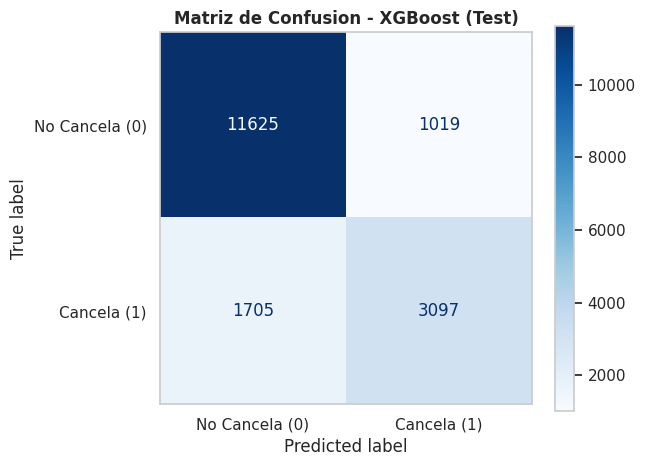

In [74]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, roc_curve, auc

# generacion de predicciones del modelo elegido (XGBoost)
y_pred_xgb = pipe_xgb.predict(X_test)
y_proba_xgb = pipe_xgb.predict_proba(X_test)[:, 1]

# matriz de confusion
cm_xgb = confusion_matrix(y_test, y_pred_xgb)

fig, ax = plt.subplots(figsize=(6, 5))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_xgb,
    display_labels=['No Cancela (0)', 'Cancela (1)']
)
disp.plot(cmap='Blues', ax=ax, values_format='d')
plt.title('Matriz de Confusion - XGBoost (Test)', fontsize=12, fontweight='bold')
plt.grid(False)
plt.show()

**Interpretación de la Matriz de Confusión (`XGBoost`):**
Sobre las **17.446 reservas** evaluadas en Test, el modelo acierta en **14.722 casos (84.39%)**:
* **Detección de bajas reales (`3.097` Verdaderos Positivos):** El modelo anticipa correctamente casi 2 de cada 3 cancelaciones reales (`Recall = 64.49%`), permitiendo al hotel gestionar preventivamente esas habitaciones.
* **Control de falsas alarmas (`1.019` Falsos Positivos):** Solo el 8.1% de los clientes que efectivamente asisten son marcados por error como riesgosos (`1.019` sobre `12.644`), lo que hace seguro aplicar acciones comerciales (como reconfirmación o señas) sin incomodar masivamente a huéspedes seguros.
* **Margen de mejora (`1.705` Falsos Negativos):** Existen 1.705 cancelaciones que el modelo no llega a anticipar con el umbral estándar de 0.50 (bajas de último momento sin señales previas en el historial).

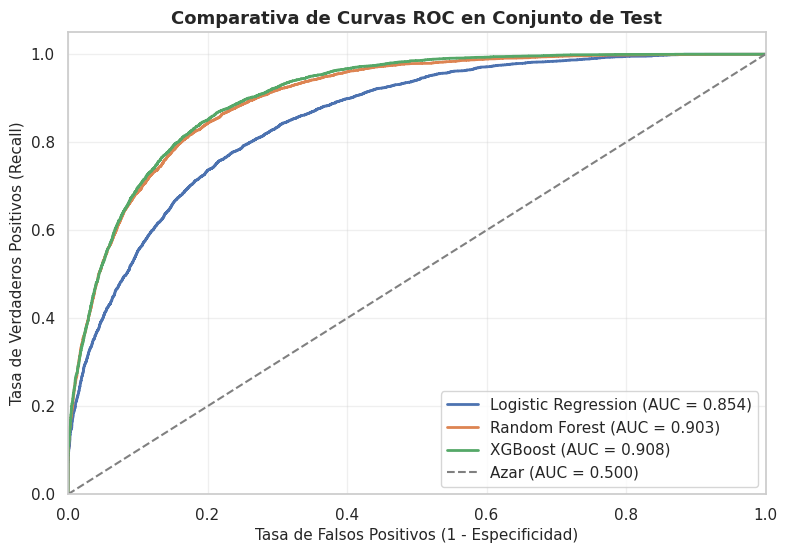

In [75]:
# curva ROC comparativa entre los modelos
plt.figure(figsize=(9, 6))

modelos_curva = {
    'Logistic Regression': pipe_lr,
    'Random Forest': pipe_rf,
    'XGBoost': pipe_xgb
}

for nombre, mod in modelos_curva.items():
    probas = mod.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, probas)
    roc_auc_val = auc(fpr, tpr)
    plt.plot(fpr, tpr, lw=2, label=f'{nombre} (AUC = {roc_auc_val:.3f})')

plt.plot([0, 1], [0, 1], color='gray', linestyle='--', lw=1.5, label='Azar (AUC = 0.500)')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Tasa de Falsos Positivos (1 - Especificidad)', fontsize=11)
plt.ylabel('Tasa de Verdaderos Positivos (Recall)', fontsize=11)
plt.title('Comparativa de Curvas ROC en Conjunto de Test', fontsize=13, fontweight='bold')
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

**Lectura de las Curvas ROC para el negocio:**
* **El valor de cruzar variables:** La diferencia entre la curva azul (`Regresión Logística`, con 0.854) y las dos superiores (`Random Forest` y `XGBoost`, arriba de 0.90) confirma lo que vimos en el análisis exploratorio: un cliente no cancela por un único motivo aislado, sino por una combinación de factores (anticipación, canal de venta, país y pedidos especiales) que los modelos de árboles captan mucho mejor.
* **Impacto práctico en la gestión de reservas (`XGBoost` - AUC 0.908):** La curva verde nos muestra qué tan flexible es el modelo si el hotel decide ajustar su nivel de alerta. Por ejemplo, si la gerencia está dispuesta a tolerar un **20% de falsas alarmas** (contactar por precaución a algunos huéspedes que igual iban a venir), `XGBoost` permite detectar a tiempo cerca del **85% de todas las cancelaciones reales**, frente al ~74% que lograría el modelo lineal. Esto da una base muy sólida para decidir a qué reservas pedirles reconfirmación o pago anticipado sin desgastar al cliente fiel.

### 9.1. Variables con mayor peso en las decisiones del modelo de XGBoost)



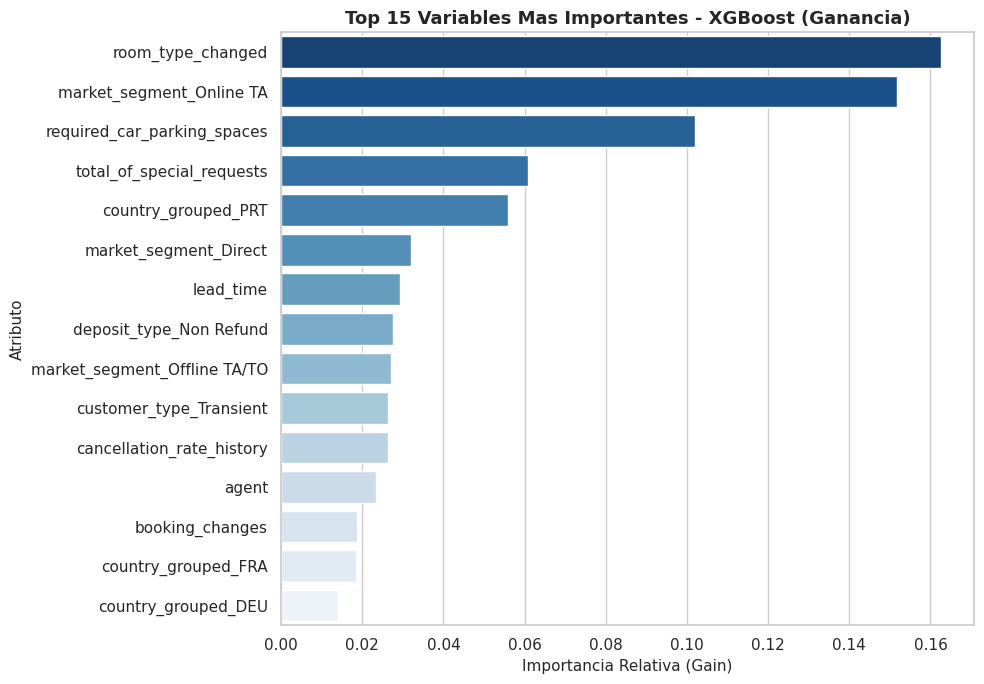

TOP 10 VARIABLES DETERMINANTES - XGBOOST
                     Feature  Importancia
           room_type_changed     0.162590
    market_segment_Online TA     0.151861
 required_car_parking_spaces     0.101973
   total_of_special_requests     0.060923
         country_grouped_PRT     0.055949
       market_segment_Direct     0.031929
                   lead_time     0.029188
     deposit_type_Non Refund     0.027670
market_segment_Offline TA/TO     0.027005
     customer_type_Transient     0.026424


In [76]:
# extraccion de nombres de columnas procesadas desde el pipeline de XGBoost
prep_xgb = pipe_xgb.named_steps['preprocessor']
nombres_numericas = columnas_numericas
nombres_categoricas = (
    prep_xgb.named_transformers_['cat']
    .named_steps['encoder']
    .get_feature_names_out(columnas_categoricas)
    .tolist()
)
nombres_features = nombres_numericas + nombres_categoricas

# extraccion de importancias de caracteristicas del clasificador XGBoost
importancias_xgb = pipe_xgb.named_steps['classifier'].feature_importances_

df_importancias = pd.DataFrame({
    'Feature': nombres_features,
    'Importancia': importancias_xgb
}).sort_values(by='Importancia', ascending=False)

# visualizacion del top 15 de caracteristicas mas influyentes
plt.figure(figsize=(10, 7))
sns.barplot(
    data=df_importancias.head(15),
    x='Importancia',
    y='Feature',
    hue='Feature',
    palette='Blues_r',
    legend=False
)
plt.title('Top 15 Variables Mas Importantes - XGBoost (Ganancia)', fontsize=13, fontweight='bold')
plt.xlabel('Importancia Relativa (Gain)', fontsize=11)
plt.ylabel('Atributo', fontsize=11)
plt.tight_layout()
plt.show()

# impresion de las 10 principales en consola
print("=" * 55)
print("TOP 10 VARIABLES DETERMINANTES - XGBOOST")
print("=" * 55)
print(df_importancias.head(10).to_string(index=False))

**Lectura de las variables más importantes para el negocio:**

1. **Variables operativas más fuertes:**
   * `room_type_changed` (16.26%), `required_car_parking_spaces` (10.20%) y `total_of_special_requests` (6.09%) operan como fuertes factores de retención: los huéspedes que interactúan con el hotel, solicitan servicios o reciben reubicaciones tienen una probabilidad mínima de cancelar.
2. **Variable volatil:**
   * `market_segment_Online TA` (15.19%) es el canal más crítico en volatilidad debido a la facilidad de reserva sin costo inicial.
3. **Confirmación de nuestras Hipótesis Iniciales (H1 y H2):**
   * La presencia de `lead_time` (2.92% — H1) y `deposit_type_Non Refund` (2.77% — H2) dentro del Top 10 confirma lo que planteamos al inicio del proyecto: tanto la anticipación de la compra como el tipo de depósito son factores decisivos para anticipar si un cliente va a cancelar.

### 9.2. Interpretabilidad Local y Global con SHAP
Aplicamos SHAP para ver que factores tienen peso en la dirección del target.

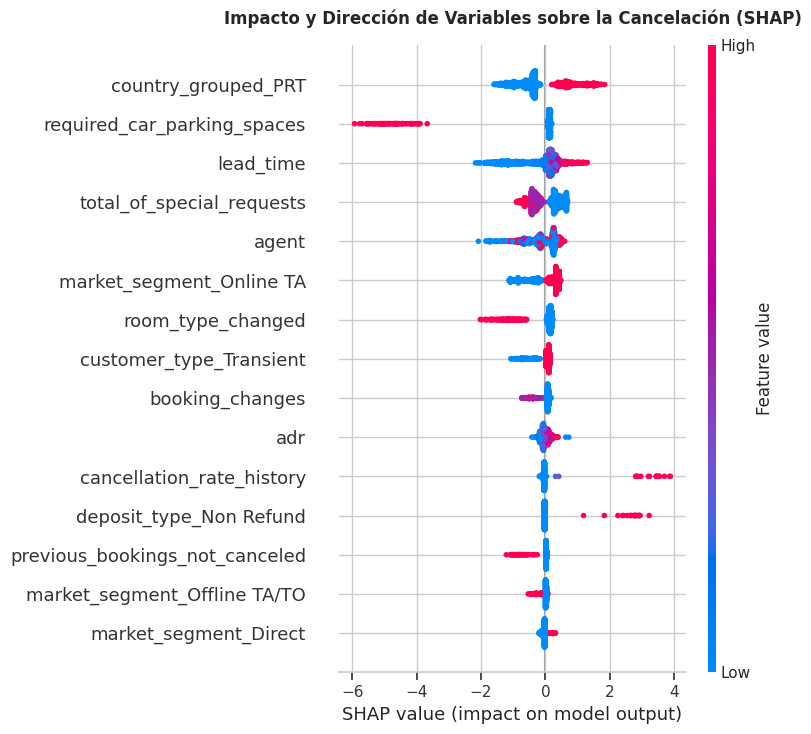

In [81]:
import shap

# Extraemos el preprocesador y el modelo entrenado directamente desde pipe_xgb
prep_step = pipe_xgb.named_steps['preprocessor']
xgb_model = pipe_xgb.named_steps['classifier']

# Transformamos una muestra representativa de X_test conservando nombres limpios de columnas
X_test_transformed = prep_step.transform(X_test)
if hasattr(X_test_transformed, "toarray"):
    X_test_transformed = X_test_transformed.toarray()

feature_names_clean = [col.split('__')[-1] for col in prep_step.get_feature_names_out()]
X_shap_sample = pd.DataFrame(X_test_transformed, columns=feature_names_clean).sample(1000, random_state=42)

# Cálculo de valores SHAP y visualización Summary Plot
explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(X_shap_sample)

plt.figure(figsize=(10, 7))
shap.summary_plot(shap_values, X_shap_sample, max_display=15, show=False)
plt.title('Impacto y Dirección de Variables sobre la Cancelación (SHAP)', fontsize=12, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

**Lectura del SHAP:**
* **Factores que impulsan la cancelación (valores SHAP positivos, hacia la derecha):** Valores altos (puntos rojos) en `lead_time`, reservas canalizadas por agencias online (`market_segment_Online TA`), tarifas elevadas (`adr`) y antecedentes de bajas (`cancellation_rate_history`) empujan fuertemente la predicción hacia la cancelación.
* **Factores de retención (valores SHAP negativos, hacia la izquierda):** La presencia de solicitudes especiales (`total_of_special_requests`), el pedido de cochera (`required_car_parking_spaces`), las modificaciones activas en la reserva (`booking_changes`) y la reasignación de habitación (`room_type_changed`) desplazan drásticamente la probabilidad hacia el *check-in* efectivo, validando las hipótesis operativas del negocio.

### 9.3. Evaluación del Costo del error


* **Falso Negativo (Costo Alto — Habitación vacía):** El modelo confía en que el huésped vendrá, pero cancela sobre la fecha. Si no se llega a revender la noche, se pierde el 100% de la tarifa (*ADR*).
* **Falso Positivo (Costo Bajo — Alerta preventiva):** El modelo advierte riesgo de cancelación, pero el cliente finalmente asiste. El costo operativo es mínimo: enviar un recordatorio de reconfirmación, ofrecer un beneficio por pago anticipado o gestionar un margen controlado de sobreventa con tiempo.

Buscaremos punto de corte, analizando `Precision`, `Recall` y `F1-Score` para detectar bajas sin falsas alarmas

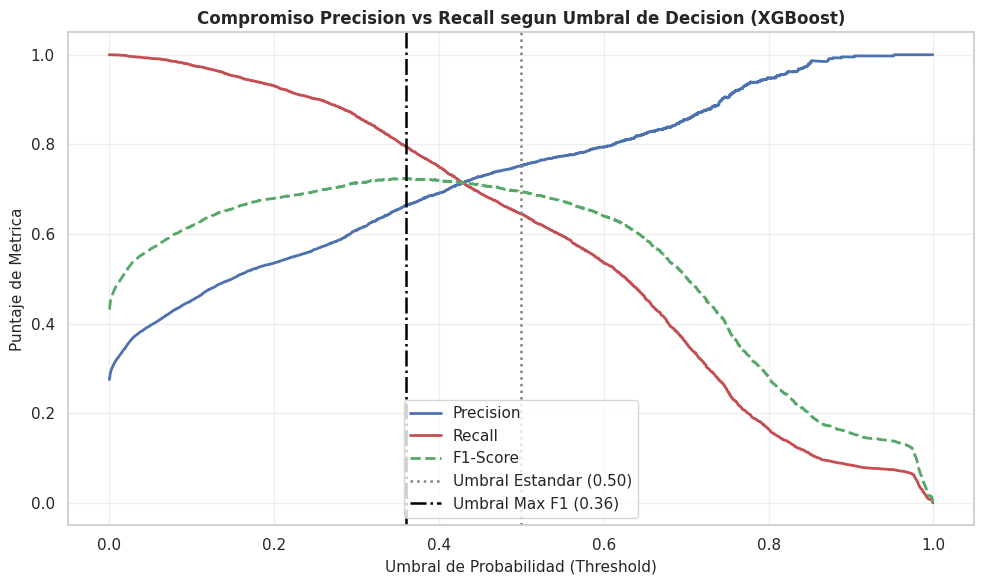

RESULTADOS EN UMBRAL OPTIMO (MAX F1-SCORE)
Umbral optimo estadistico (Max F1): 0.3598
Precision en umbral optimo:         0.6642
Recall en umbral optimo:            0.7957
F1-Score en umbral optimo:          0.7240


In [77]:
import numpy as np
from sklearn.metrics import precision_recall_curve

# probabilidades de cancelacion predichas por XGBoost en test
y_proba_xgb = pipe_xgb.predict_proba(X_test)[:, 1]

# calculo de precision, recall y umbrales para cada punto de corte
precisiones, recalls, umbrales = precision_recall_curve(y_test, y_proba_xgb)

# calculo de f1-score para cada umbral y busqueda del maximo
f1_scores = 2 * (precisiones[:-1] * recalls[:-1]) / (precisiones[:-1] + recalls[:-1] + 1e-10)
indice_optimo_f1 = np.argmax(f1_scores)
umbral_optimo_f1 = umbrales[indice_optimo_f1]

# visualizacion del compromiso precision vs recall segun el umbral
plt.figure(figsize=(10, 6))
plt.plot(umbrales, precisiones[:-1], label='Precision', color='#4C72B0', lw=2)
plt.plot(umbrales, recalls[:-1], label='Recall', color='#C44E52', lw=2)
plt.plot(umbrales, f1_scores, label='F1-Score', color='#55A868', linestyle='--', lw=2)

plt.axvline(0.50, color='gray', linestyle=':', lw=1.8, label='Umbral Estandar (0.50)')
plt.axvline(umbral_optimo_f1, color='black', linestyle='-.', lw=1.8, label=f'Umbral Max F1 ({umbral_optimo_f1:.2f})')

plt.title('Compromiso Precision vs Recall segun Umbral de Decision (XGBoost)', fontsize=12, fontweight='bold')
plt.xlabel('Umbral de Probabilidad (Threshold)', fontsize=11)
plt.ylabel('Puntaje de Metrica', fontsize=11)
plt.legend(loc='lower center')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("=" * 55)
print("RESULTADOS EN UMBRAL OPTIMO (MAX F1-SCORE)")
print("=" * 55)
print(f"Umbral optimo estadistico (Max F1): {umbral_optimo_f1:.4f}")
print(f"Precision en umbral optimo:         {precisiones[indice_optimo_f1]:.4f}")
print(f"Recall en umbral optimo:            {recalls[indice_optimo_f1]:.4f}")
print(f"F1-Score en umbral optimo:          {f1_scores[indice_optimo_f1]:.4f}")

### Conclusiones y valores a ajustar

1. **Nuevo punto de corte comercial (36%):**
   * Al buscar el mejor equilibrio con el `F1-Score`, el umbral óptimo baja a **36% (0.3598)**, activando la alerta preventiva cuando una reserva supera esta probabilidad de baja.
2. **Salto en la detección de cancelaciones:**
   * El **Recall sube del 64.49% al 79.57% (+15.08 puntos porcentuales)**, permitiendo anticipar casi **8 de cada 10 cancelaciones reales** a tiempo.
   * La **Precision se ubica en 66.42%**, asegurando que dos de cada tres alertas emitidas correspondan a una cancelación efectiva, sin saturar al equipo con falsas alarmas.
   * El **F1-Score mejora a 72%** (frente al 69% del umbral estándar).
3. **Ajustes:**
   * Se adopta el umbral de **0.36** para disparar acciones preventivas tempranas (pedidos de reconfirmación, incentivos por pago anticipado o cupos controlados de *overbooking*) sobre las reservas marcadas en riesgo.

### 9.4. Aplicación de cambios del umbral y Evaluación del nuevo modelo

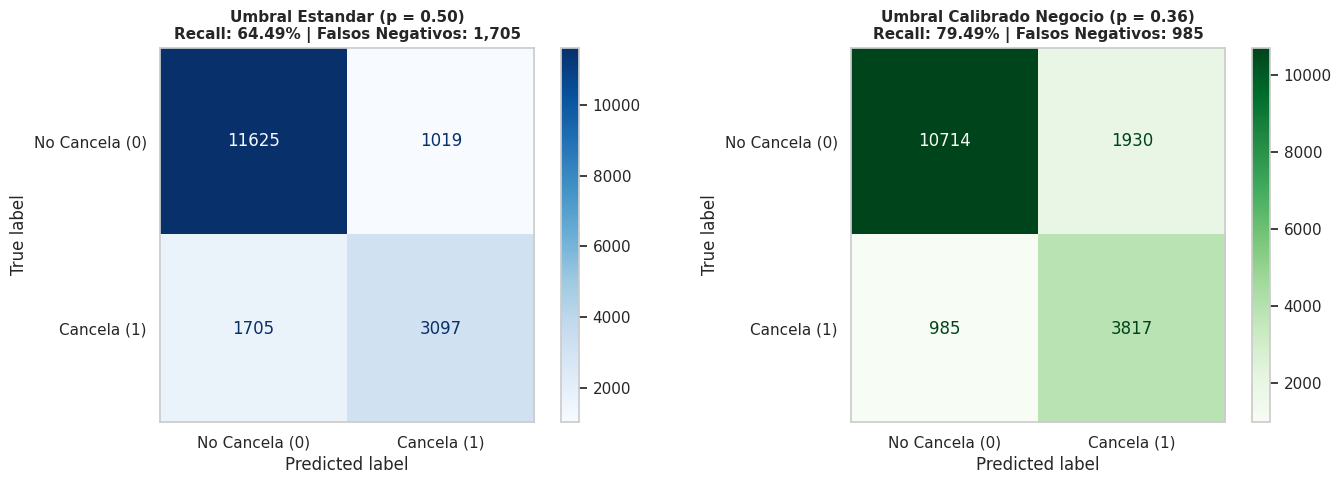

IMPACTO OPERATIVO TRAS APLICAR EL NUEVO UMBRAL (0.36)
Cancelaciones no detectadas antes (p=0.50) : 1,705 reservas
Cancelaciones no detectadas ahora (p=0.36) : 985 reservas
Habitaciones salvadas de quedar vacias     : 720 reservas (-42.2% de bajas sorpresa)


In [78]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, recall_score

# 1. aplicamos formalmente el nuevo umbral calibrado (0.36)
umbral_negocio = 0.36
y_pred_base = (y_proba_xgb >= 0.50).astype(int)
y_pred_calibrado = (y_proba_xgb >= umbral_negocio).astype(int)

# 2. matrices de confusion y metricas para los nuevos titulos
cm_base = confusion_matrix(y_test, y_pred_base)
cm_calibrado = confusion_matrix(y_test, y_pred_calibrado)

rec_base = recall_score(y_test, y_pred_base) * 100
rec_cal = recall_score(y_test, y_pred_calibrado) * 100
fn_base = cm_base[1, 0]
fn_calibrado = cm_calibrado[1, 0]
recuperadas = fn_base - fn_calibrado

# 3. visualizacion comparativa lado a lado
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

disp1 = ConfusionMatrixDisplay(
    confusion_matrix=cm_base,
    display_labels=['No Cancela (0)', 'Cancela (1)']
)
disp1.plot(cmap='Blues', ax=axes[0], values_format='d')
axes[0].set_title(
    f'Umbral Estandar (p = 0.50)\nRecall: {rec_base:.2f}% | Falsos Negativos: {fn_base:,}',
    fontsize=11,
    fontweight='bold'
)
axes[0].grid(False)

disp2 = ConfusionMatrixDisplay(
    confusion_matrix=cm_calibrado,
    display_labels=['No Cancela (0)', 'Cancela (1)']
)
disp2.plot(cmap='Greens', ax=axes[1], values_format='d')
axes[1].set_title(
    f'Umbral Calibrado Negocio (p = {umbral_negocio})\nRecall: {rec_cal:.2f}% | Falsos Negativos: {fn_calibrado:,}',
    fontsize=11,
    fontweight='bold'
)
axes[1].grid(False)

plt.tight_layout()
plt.show()

# resumen de impacto en numeros exactos
print("=" * 65)
print("IMPACTO OPERATIVO TRAS APLICAR EL NUEVO UMBRAL (0.36)")
print("=" * 65)
print(f"Cancelaciones no detectadas antes (p=0.50) : {fn_base:,} reservas")
print(f"Cancelaciones no detectadas ahora (p=0.36) : {fn_calibrado:,} reservas")
print(f"Habitaciones salvadas de quedar vacias     : {recuperadas:,} reservas (-{recuperadas/fn_base*100:.1f}% de bajas sorpresa)")
print("=" * 65)

###  Conclusión de la Calibración de Umbral (p = 0.36)

1. **Mitigación de Falsos Negativos:** Las cancelaciones imprevistas descienden de 1.705 a 985 reservas, lo que implica una reducción del 42.2% en bajas sorpresa.

2. **Costo operativo controlado:** Para lograr ese rescate, las falsas alarmas aumentan en 911 casos (`de 1.019 a 1.930`). Dado que una acción preventiva temprana (mensaje de reconfirmación o incentivo de pago anticipado) tiene costo marginal casi nulo frente a perder noches completas de alojamiento, el balance financiero favorece ampliamente este punto de corte.

## 10. Simulación Económica e Impacto de Negocio

Para cuantificar el retorno real del proyecto sobre las **17.446 reservas** de prueba, comparamos la **situación actual del hotel (sin modelo predictivo)** frente a la implementación de **XGBoost** tanto en su configuración estándar (`0.50`) como con el umbral calibrado para el negocio (`0.36`).

**Parámetros operativos tomados del EDA:**
* **Ingreso promedio por reserva:** **353,60 €** (`ADR` de 104,00 € × `total_stay` de 3,4 noches).
* **Costo de Habitación Vacía (Baja no detectada):** Pérdida del 100% de la reserva (**353,60 €**).
* **Costo de Alerta Preventiva (Falsa alarma):** **5,00 €** por gestión proactiva de contacto/reconfirmación.
* **Tasa de recupero sobre bajas anticipadas:** **70%** (vía reventa temprana, señas o sobreventa controlada).

In [79]:
# parametros financieros basados en el eda
adr_promedio = 104.0
noches_promedio = 3.4
valor_reserva = adr_promedio * noches_promedio
costo_falso_positivo = 5.0
tasa_recuperacion = 0.70

# escenario 0: sin modelo (situacion actual / dummy classifier)
total_cancelaciones = int(y_test.sum())
vp_sin, fp_sin, fn_sin = 0, 0, total_cancelaciones
perdida_sin_modelo = fn_sin * valor_reserva
beneficio_sin_modelo = 0.0

# escenario 1 y 2: extraccion desde las matrices reales de test
fp_base, fn_base, vp_base = cm_base[0, 1], cm_base[1, 0], cm_base[1, 1]
fp_opt, fn_opt, vp_opt = cm_calibrado[0, 1], cm_calibrado[1, 0], cm_calibrado[1, 1]

# calculos para umbral estandar (0.50)
ingreso_rec_base = vp_base * valor_reserva * tasa_recuperacion
costo_fp_base = fp_base * costo_falso_positivo
perdida_fn_base = fn_base * valor_reserva
beneficio_neto_base = ingreso_rec_base - costo_fp_base

# calculos para umbral calibrado (0.36)
ingreso_rec_opt = vp_opt * valor_reserva * tasa_recuperacion
costo_fp_opt = fp_opt * costo_falso_positivo
perdida_fn_opt = fn_opt * valor_reserva
beneficio_neto_opt = ingreso_rec_opt - costo_fp_opt

# tabla consolidada contra la situacion actual sin modelo
df_impacto = pd.DataFrame({
    'Escenario': [
        '1. Sin Modelo (Situacion Actual)',
        '2. XGBoost Estandar (p = 0.50)',
        '3. XGBoost Calibrado (p = 0.36)'
    ],
    'Bajas Detectadas': [f"{vp_sin:,}", f"{vp_base:,}", f"{vp_opt:,}"],
    'Bajas Sorpresa (FN)': [f"{fn_sin:,}", f"{fn_base:,}", f"{fn_opt:,}"],
    'Perdida por Hab. Vacia': [
        f"{perdida_sin_modelo:,.2f} €",
        f"{perdida_fn_base:,.2f} €",
        f"{perdida_fn_opt:,.2f} €"
    ],
    'Costo Gestion Alertas': [
        "0.00 €",
        f"{costo_fp_base:,.2f} €",
        f"{costo_fp_opt:,.2f} €"
    ],
    'Beneficio Neto Recuperado': [
        "0.00 €",
        f"+{beneficio_neto_base:,.2f} €",
        f"+{beneficio_neto_opt:,.2f} €"
    ]
})

print("=" * 95)
print("SIMULACION ECONOMICA EN CONJUNTO DE TEST (17,446 RESERVAS): SIN MODELO VS. XGBOOST")
print("=" * 95)
df_impacto

SIMULACION ECONOMICA EN CONJUNTO DE TEST (17,446 RESERVAS): SIN MODELO VS. XGBOOST


,Escenario,Bajas Detectadas,Bajas Sorpresa (FN),Perdida por Hab. Vacia,Costo Gestion Alertas,Beneficio Neto Recuperado
0,1. Sin Modelo (Situacion Actual),0,"4,802","1,697,987.20 €",0.00 €,0.00 €
1,2. XGBoost Estandar (p = 0.50),"3,097","1,705","602,888.00 €","5,095.00 €","+761,474.44 €"
2,3. XGBoost Calibrado (p = 0.36),"3,817",985,"348,296.00 €","9,650.00 €","+935,133.84 €"


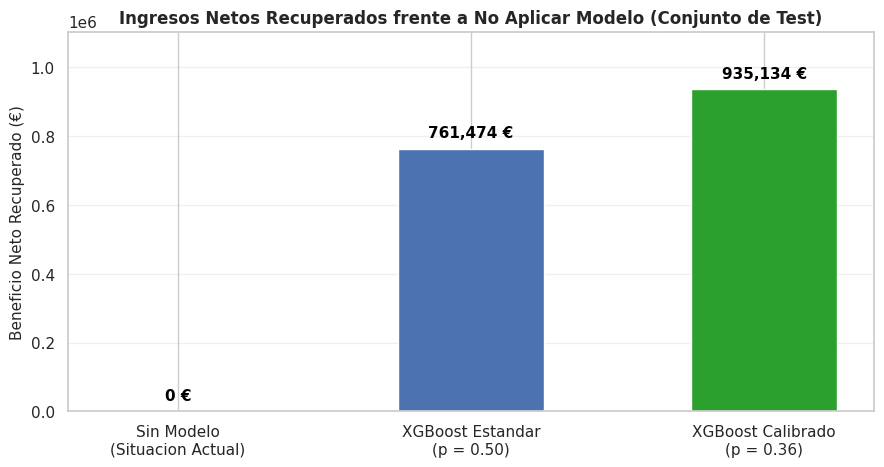

Beneficio total vs. no tener modelo: +935,133.84 €
Valor adicional aportado por calibrar el umbral (0.36 vs 0.50): +173,659.40 €
Reduccion de perdidas por habitaciones vacias sorpresa: -79.5%


In [80]:
# visualizacion comparativa de los 3 escenarios
plt.figure(figsize=(9, 5))

escenarios = [
    'Sin Modelo\n(Situacion Actual)',
    'XGBoost Estandar\n(p = 0.50)',
    'XGBoost Calibrado\n(p = 0.36)'
]
beneficios = [beneficio_sin_modelo, beneficio_neto_base, beneficio_neto_opt]
colores = ['#B0B0B0', '#4C72B0', '#2CA02C']

barras = plt.bar(escenarios, beneficios, color=colores, width=0.5)

for barra in barras:
    altura = barra.get_height()
    posicion_y = altura + 25000
    plt.text(
        barra.get_x() + barra.get_width() / 2.,
        posicion_y,
        f"{altura:,.0f} €",
        ha='center',
        va='bottom',
        color='black',
        fontweight='bold',
        fontsize=11
    )

plt.title(
    'Ingresos Netos Recuperados frente a No Aplicar Modelo (Conjunto de Test)',
    fontsize=12,
    fontweight='bold'
)
plt.ylabel('Beneficio Neto Recuperado (€)', fontsize=11)
plt.ylim(0, max(beneficios) * 1.18)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

reduccion_perdida_pct = ((perdida_sin_modelo - perdida_fn_opt) / perdida_sin_modelo) * 100
print(f"Beneficio total vs. no tener modelo: +{beneficio_neto_opt:,.2f} €")
print(f"Valor adicional aportado por calibrar el umbral (0.36 vs 0.50): +{beneficio_neto_opt - beneficio_neto_base:,.2f} €")
print(f"Reduccion de perdidas por habitaciones vacias sorpresa: -{reduccion_perdida_pct:.1f}%")

### Análisis del Impacto en el Negocio


1. **El impacto de incorporar Machine Learning :**
   * Sin una herramienta predictiva, las 4.802 cancelaciones imprevistas representan una pérdida bruta de **1.697.987,20 €** en habitaciones que corren riesgo de quedar vacías.
   * Implementar `XGBoost` calibrado permite anticipar la gran mayoría de esas bajas para activar acciones de retención o reventa temprana, logrando un **beneficio neto recuperado de +935.133,84 €** (ya descontados los **9.650,00 €** del costo operativo de gestionar las alertas preventivas).
2. **El valor comercial de ajustar el umbral (`p = 0.36` vs. `p = 0.50`):**
   * Quedarse con el corte estándar por defecto (`0.50`) permitía anticipar 3.097 cancelaciones, dejando todavía 1.705 bajas sin detectar.
   * Al bajar el umbral a **0.36**, el hotel logra interceptar a tiempo **3.817 cancelaciones reales**, reduciendo las bajas sorpresa a solo **985 reservas** (**-79,5% de habitaciones vacías imprevistas** frente a no tener modelo).
   * Por ende, Calibrar la sensibilidad del modelo según la realidad financiera del hotel suma **+173.659,40 € adicionales de ganancia neta** sin cambiar de algoritmo.

## 11. Conclusión y Recomendaciones

En esta última etapa integramos los hallazgos estadísticos, el comportamiento interno del modelo ganador y el retorno económico simulado para traducirlos en decisiones operativas concretas y contrastar los supuestos planteados al inicio de la investigación.

### 11.1. Recomendaciones Estratégicas y Plan de Acción

A partir de las variables más determinantes identificadas por `XGBoost` y la capacidad de detección alcanzada, proponemos cuatro líneas de acción para la gerencia del hotel:

#### 1. Gestión diferenciada por canal de venta (`market_segment_Online TA` vs. `Direct`)
* **Diagnóstico:** Las agencias online (OTAs) concentran el mayor volumen de reservas especulativas por la facilidad de reservar sin pago inicial y cancelar a un clic.
* **Acción operativa:**
  * **Ventanas de cancelación escalonadas:** Acortar el plazo de cancelación gratuita (pasando de 48 horas antes a una ventana de 7 a 14 días previos) en reservas de OTAs realizadas con más de 60 días de anticipación (`lead_time > 60`).
  * **Tracción hacia el canal directo:** Ofrecer beneficios de bajo costo operativo (como *late check-out*, bebida de bienvenida o prioridad de *upgrade* sujeto a disponibilidad) para incentivar la reserva en la web propia del hotel, donde la tasa de asistencia es mucho más firme.

#### 2. Rediseño de señas y validación de medios de pago (`deposit_type`)
* **Diagnóstico:** Las reservas marcadas como *Non Refund* mostraron una anomalía de altísima cancelación asociada a bloqueos de intermediarios y tarjetas sin fondos o inválidas.
* **Acción operativa:**
  * **Anticipos parciales flexibles:** Reemplazar las tarifas rígidas 100% no reembolsables en reservas lejanas (`lead_time > 90` días) por una seña inicial del 20%–30% al momento de reservar, filtrando la reserva puramente especulativa.
  * **Preautorización preventiva según riesgo:** Automatizar la validación de la tarjeta de crédito entre 7 y 10 días antes del ingreso únicamente sobre aquellas reservas que el modelo marque en zona de alerta (`probabilidad >= 0.36`).

#### 3. Política de Sobreventa Inteligente (*Smart Overbooking*)
* **Diagnóstico:** Operar sin modelo dejaba al hotel expuesto a 4.802 bajas imprevistas en la muestra evaluada, perdiendo el 100% de la tarifa en las noches no revendidas.
* **Acción operativa:**
  * **Cupos dinámicos respaldados por datos:** Habilitar un margen de sobreventa controlado (entre un 5% y un 8% en fechas de alta demanda y categorías estándar), apalancado en que el modelo anticipa el **79,5%** de las cancelaciones reales.
  * **Convenios de relocalización (*Walk agreements*):** Mantener acuerdos recíprocos con hoteles cercanos de igual o mayor categoría para cubrir eventuales desvíos puntuales a un costo pactado y sin dañar la reputación comercial.

#### 4. Contacto temprano para generar compromiso (`special_requests` y `parking`)
* **Diagnóstico:** Los huéspedes que piden cochera, requerimientos especiales o interactúan con la asignación de habitación (`room_type_changed`) casi no cancelan: el contacto previo funciona como un ancla real de viaje.
* **Acción operativa:**
  * **Puntos de contacto pre-arribo (*Pre-arrival touchpoints*):** Enviar mensajes automáticos por WhatsApp o email 15 y 5 días antes del *check-in* ofreciendo reservar estacionamiento, elegir preferencias de habitación (piso, cuna, tipo de cama) o informar horario de llegada. Además de fortalecer el compromiso del viajero, quien ya decidió no viajar suele aprovechar ese contacto para avisar su baja a tiempo, liberando la habitación para su reventa inmediata.

### 11.2. Validación de Hipótesis Iniciales y Cierre del Proyecto

* **Hipótesis 1 (`lead_time` — Validada):** Se confirma que a mayor anticipación de compra, mayor es la probabilidad de cancelación. El tiempo de espera demostró ser un factor estructural tanto en el EDA como dentro del Top 10 de variables decisivas del modelo (`2,92%` de ganancia), respaldando la aplicación de políticas de cancelación y señas escalonadas según la lejanía del viaje.
* **Hipótesis 2 (`deposit_type` y canales de distribución — Validada con matiz operativo):** Se confirma que las condiciones de reserva y el canal comercial condicionan directamente la tasa de abandono. Mientras las agencias online (`Online TA`, `15,19%` de importancia) traccionan la volatilidad por su flexibilidad sin cargo inicial, el segmento `Non Refund` evidenció un comportamiento atípico vinculado a bloqueos especulativos e intermediarios, justificando migrar hacia anticipos parciales y preautorizaciones tempranas.
* **Síntesis Final:** La combinación de ingeniería de atributos —liderada por señales de compromiso operativo como `room_type_changed` (`16,26%`), cochera (`10,20%`) y pedidos especiales (`6,09%`)— junto con la calibración comercial del umbral a `p = 0.36`[cite: 2] permitió convertir una pérdida pasiva en una herramienta activa de *Revenue Management*, capaz de anticipar casi **8 de cada 10 cancelaciones reales** (`79,49%`[cite: 2]) y recuperar **+935.133,84 € netos** sobre el conjunto evaluado.